
# Forecasting Weekly Grocery Expenditure

**Course:** Predictive Analytics (22ADE772)  
**Topic:** Time Series Forecasting — T7

## 1. Introduction

The objective of this project is to analyse weekly household grocery expenditure and develop a simple forecasting approach to estimate expenditure for the following week.

The project uses weekly grocery expenditure observations collected for eight consecutive weeks. The workflow includes data inspection, data preparation, exploratory visualisation, baseline forecasting, and chronological model evaluation.

## 2. Objectives

- Understand the pattern of weekly grocery expenditure.
- Inspect and prepare the time-series dataset.
- Visualise changes in expenditure over time.
- Implement naive and mean forecasting methods.
- Compare forecasts using Mean Absolute Error (MAE).
- Estimate expenditure for the next week and discuss limitations.


In [4]:
# Import libraries for our grocery expenditure project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Load the weekly grocery expenditure dataset

file_path = Path("../data/weekly_expenditure_data.csv")
df = pd.read_csv(file_path)

# Display the first five rows
df.head()

,Week,week_start,week_end,grocery_expenditure_inr,number_of_purchases,notes
0,1,2026-08-01,2026-08-07,1765,5,Regular weekly grocery shopping
1,2,2026-08-08,2026-08-14,2140,5,Restocked dairy and vegetables
2,3,2026-08-15,2026-08-21,1890,6,Typical household grocery purchases
3,4,2026-08-22,2026-08-28,2675,6,Higher spending due to pantry staples
4,5,2026-08-29,2026-09-04,2310,6,Included monthly staples purchase


In [6]:
# Check the structure of our dataset

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape: (8, 6)

Column names:
['Week', 'week_start', 'week_end', 'grocery_expenditure_inr', 'number_of_purchases', 'notes']

Data types:
Week                       int64
week_start                   str
week_end                     str
grocery_expenditure_inr    int64
number_of_purchases        int64
notes                        str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Week                     8 non-null      int64
 1   week_start               8 non-null      str  
 2   week_end                 8 non-null      str  
 3   grocery_expenditure_inr  8 non-null      int64
 4   number_of_purchases      8 non-null      int64
 5   notes                    8 non-null      str  
dtypes: int64(3), str(3)
memory usage: 516.0 bytes


In [7]:
# Check data quality

print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nBasic statistical summary:")
df.describe(include="all")

Missing values in each column:
Week                       0
week_start                 0
week_end                   0
grocery_expenditure_inr    0
number_of_purchases        0
notes                      0
dtype: int64

Number of duplicate rows:
0

Basic statistical summary:


,Week,week_start,week_end,grocery_expenditure_inr,number_of_purchases,notes
count,8.00000,8,8,8.000000,8.000000,8
unique,NaN,8,8,NaN,NaN,8
top,NaN,2026-08-01,2026-08-07,NaN,NaN,Regular weekly grocery shopping
freq,NaN,1,1,NaN,NaN,1
mean,4.50000,NaN,NaN,2166.250000,5.625000,NaN
std,2.44949,NaN,NaN,307.869986,0.517549,NaN
min,1.00000,NaN,NaN,1765.000000,5.000000,NaN
25%,2.75000,NaN,NaN,1961.250000,5.000000,NaN
50%,4.50000,NaN,NaN,2107.500000,6.000000,NaN
75%,6.25000,NaN,NaN,2355.000000,6.000000,NaN


In [8]:

# Convert date columns from text to datetime format

df["week_start"] = pd.to_datetime(df["week_start"])
df["week_end"] = pd.to_datetime(df["week_end"])

# Sort the observations in chronological order
df = df.sort_values("week_start").reset_index(drop=True)

# Display the dates and expenditure
df[["Week", "week_start", "week_end", "grocery_expenditure_inr"]]


,Week,week_start,week_end,grocery_expenditure_inr
0,1,2026-08-01,2026-08-07,1765
1,2,2026-08-08,2026-08-14,2140
2,3,2026-08-15,2026-08-21,1890
3,4,2026-08-22,2026-08-28,2675
4,5,2026-08-29,2026-09-04,2310
5,6,2026-09-05,2026-09-11,1985
6,7,2026-09-12,2026-09-18,2490
7,8,2026-09-19,2026-09-25,2075


In [9]:

# Check the gap between consecutive weekly observations

df["days_between_weeks"] = df["week_start"].diff().dt.days

print("Days between weekly observations:")
print(df["days_between_weeks"])

print("\nAre all observations exactly 7 days apart?")
print(df["days_between_weeks"].dropna().eq(7).all())


Days between weekly observations:
0    NaN
1    7.0
2    7.0
3    7.0
4    7.0
5    7.0
6    7.0
7    7.0
Name: days_between_weeks, dtype: float64

Are all observations exactly 7 days apart?
True


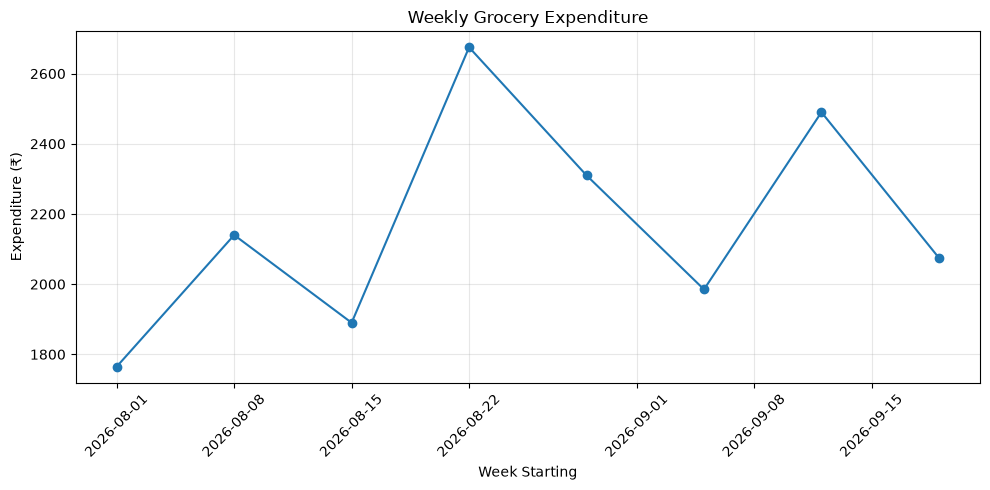

In [10]:

# Visualise weekly grocery expenditure

plt.figure(figsize=(10, 5))

plt.plot(
    df["week_start"],
    df["grocery_expenditure_inr"],
    marker="o"
)

plt.title("Weekly Grocery Expenditure")
plt.xlabel("Week Starting")
plt.ylabel("Expenditure (₹)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

# Calculate week-to-week changes in grocery expenditure

df["change_in_expenditure"] = (
    df["grocery_expenditure_inr"].diff()
)

df["percentage_change"] = (
    df["grocery_expenditure_inr"].pct_change() * 100
)

df[[
    "Week",
    "grocery_expenditure_inr",
    "change_in_expenditure",
    "percentage_change"
]].round(2)


,Week,grocery_expenditure_inr,change_in_expenditure,percentage_change
0,1,1765,NaN,NaN
1,2,2140,375.0,21.25
2,3,1890,-250.0,-11.68
3,4,2675,785.0,41.53
4,5,2310,-365.0,-13.64
5,6,1985,-325.0,-14.07
6,7,2490,505.0,25.44
7,8,2075,-415.0,-16.67


In [12]:

# Naive forecast: next week's spending equals the latest week's spending

actual_values = df["grocery_expenditure_inr"]

naive_forecast = actual_values.iloc[-1]

print("Latest observed expenditure: ₹", naive_forecast)
print("Naive forecast for next week: ₹", naive_forecast)


Latest observed expenditure: ₹ 2075
Naive forecast for next week: ₹ 2075


In [13]:

# Mean forecast: use the average of all observed weeks

mean_forecast = actual_values.mean()

print(f"Naive forecast: ₹{naive_forecast:.2f}")
print(f"Mean forecast:  ₹{mean_forecast:.2f}")


Naive forecast: ₹2075.00
Mean forecast:  ₹2166.25


In [14]:

# Evaluate forecasts using chronological walk-forward testing

values = df["grocery_expenditure_inr"].tolist()

results = []

# Start with the first five weeks
for i in range(5, len(values)):
    history = values[:i]
    actual = values[i]

    # Naive prediction: use the most recent observed week
    naive_prediction = history[-1]

    # Mean prediction: use the average of previous observations
    mean_prediction = sum(history) / len(history)

    results.append({
        "Week": i + 1,
        "Actual": actual,
        "Naive_Forecast": naive_prediction,
        "Mean_Forecast": round(mean_prediction, 2)
    })

results_df = pd.DataFrame(results)

results_df


,Week,Actual,Naive_Forecast,Mean_Forecast
0,6,1985,2310,2156.00
1,7,2490,1985,2127.50
2,8,2075,2490,2179.29


In [15]:

# Calculate Mean Absolute Error (MAE) for each method

naive_mae = (
    results_df["Actual"] - results_df["Naive_Forecast"]
).abs().mean()

mean_mae = (
    results_df["Actual"] - results_df["Mean_Forecast"]
).abs().mean()

print(f"Naive forecast MAE: ₹{naive_mae:.2f}")
print(f"Mean forecast MAE:  ₹{mean_mae:.2f}")


Naive forecast MAE: ₹415.00
Mean forecast MAE:  ₹212.60


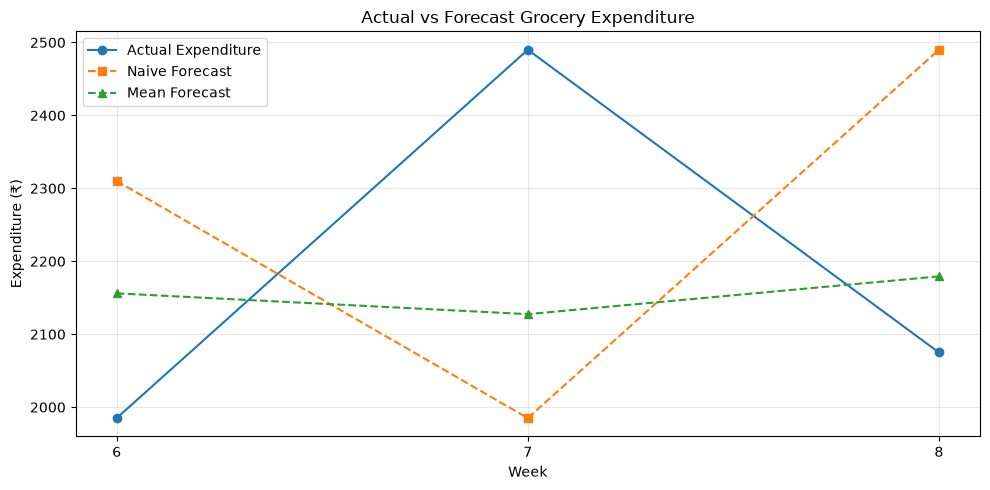

In [16]:

# Compare actual expenditure with both forecasting methods

plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Week"],
    results_df["Actual"],
    marker="o",
    label="Actual Expenditure"
)

plt.plot(
    results_df["Week"],
    results_df["Naive_Forecast"],
    marker="s",
    linestyle="--",
    label="Naive Forecast"
)

plt.plot(
    results_df["Week"],
    results_df["Mean_Forecast"],
    marker="^",
    linestyle="--",
    label="Mean Forecast"
)

plt.title("Actual vs Forecast Grocery Expenditure")
plt.xlabel("Week")
plt.ylabel("Expenditure (₹)")
plt.xticks(results_df["Week"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:

# Forecast expenditure for the next week using the latest available data

next_week_naive = actual_values.iloc[-1]
next_week_mean = actual_values.mean()

print("Forecast for Week 9")
print("-" * 30)
print(f"Naive forecast: ₹{next_week_naive:.2f}")
print(f"Mean forecast:  ₹{next_week_mean:.2f}")


Forecast for Week 9
------------------------------
Naive forecast: ₹2075.00
Mean forecast:  ₹2166.25



## 8. Results and Discussion

### 8.1 Dataset Summary

The dataset contains eight consecutive weekly observations of household grocery expenditure. The recorded expenditure ranges from ₹1,765 to ₹2,675, with an average of ₹2,166.25 per week.

The dataset contains no missing values or duplicate rows. The date checks confirm that the observations are seven days apart.

### 8.2 Forecasting Model Comparison

Two baseline forecasting methods were evaluated using chronological walk-forward testing. The first five weeks were used to initialise the forecasts, and Weeks 6–8 were used for evaluation.

| Forecasting Method | Mean Absolute Error (MAE) |
|---|---:|
| Naive Forecast | ₹415.00 |
| Mean Forecast | ₹212.60 |

The mean forecasting method produced a lower MAE than the naive method on the three evaluation observations. Therefore, it performed better on this particular test set. However, the small evaluation sample does not establish that it will consistently produce more accurate forecasts.

### 8.3 Forecast for the Next Week

Using all eight available observations, the estimated expenditure for Week 9 is:

- Naive forecast: ₹2,075.00
- Mean forecast: ₹2,166.25

These values are baseline estimates rather than guaranteed expenditure amounts.

## 9. Limitations

1. The dataset contains only eight weekly observations.
2. Some expenditure amounts were recalled from memory and may not match exact spending.
3. Only three observations were available for evaluating forecasting accuracy.
4. The analysis does not establish a reliable long-term trend or seasonal pattern.
5. Household spending may change because of restocking, prices, family needs, and other factors not represented in the dataset.

## 10. Conclusion

This project demonstrates a basic time-series forecasting workflow for weekly household grocery expenditure. The dataset was inspected, prepared, visualised, and evaluated using naive and mean forecasting methods.

The mean method achieved a lower MAE than the naive method on the limited evaluation sample. The project also demonstrates the importance of chronological evaluation and transparent reporting of data limitations.

Collecting more consecutive weeks of verified expenditure data would help support a more meaningful comparison of forecasting methods in future work.
